# Lab 1 – Faster R-CNN on ArTaxOr

In [1]:
%pip install -q lightning torchmetrics pycocotools

Note: you may need to restart the kernel to use updated packages.


## Fixed pipeline (copy of `object_detection_pipeline.py`)

In [2]:
%%writefile object_detection_pipeline.py
import argparse
import json
import os
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Dict, List, Tuple

import torch
from torch import Tensor
from torch.utils.data import DataLoader, Dataset

import torchvision
from torchvision.transforms import functional as F

import lightning.pytorch as pl
from lightning.pytorch.callbacks import LearningRateMonitor, ModelCheckpoint

from torchmetrics.detection.mean_ap import MeanAveragePrecision
from PIL import Image

MIN_BOX_SIZE = 1

# -----------------------------
# Utils
# -----------------------------
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def collate_fn(batch):
    # BEFORE: images, targets, _ = zip(*batch)
    # FIX: batch contains 2 items, we tried to unpack 3
    images, targets = zip(*batch)
    return list(images), list(targets)


# -----------------------------
# Dataset
# -----------------------------
@dataclass
class Sample:
    image_path: Path
    ann_path: Path
    order_name: str


class ArTaxOrVoTTDataset(Dataset):
    """
    Reads VoTT JSON per image. Expected keys:
      - data["asset"]["name"] -> image filename
      - data["regions"][i]["boundingBox"] -> {left, top, width, height}
      - data["regions"][i]["tags"] -> ["OrderName", ...] (optional; we fallback to folder name)
    """

    def __init__(
        self,
        samples: List[Sample],
        class_to_idx: Dict[str, int],
        train: bool = True,
        hflip_p: float = 0.5,
    ):
        self.samples = samples
        self.class_to_idx = class_to_idx
        self.train = train
        self.hflip_p = hflip_p

    def __len__(self) -> int:
        return len(self.samples)

    def _read_target(self, ann_path: Path, fallback_label: str) -> Tuple[Tensor, Tensor]:
        data = json.loads(ann_path.read_text(encoding="utf-8"))

        boxes: List[List[float]] = []
        labels: List[int] = []

        for reg in data.get("regions", []):
            bb = reg.get("boundingBox", None)
            if bb is None:
                continue

            left = float(bb["left"])
            top = float(bb["top"])
            width = float(bb["width"])
            height = float(bb["height"])
            x1, y1 = left, top
            # BEFORE: x2, y2 = left + height, top + width
            # FIX: we previously added width to height and vice versa, needed to switch places
            x2, y2 = left + width, top + height

            tag_list = reg.get("tags", []) or []
            # BEFORE: label_name = tag_list[0] if (len(tag_list) > 0) else fallback_label; 
            # if label_name not in self.class_to_idx: label_name = fallback_label
            # FIX: this is not a bug for the current dataset, however it is a guard against errors that may arise:
            # correct tag=label is taken from json tag list 1st item, which may not be the correct class (as the folder name or from class
            # list at all), so we look through all tags for the instance, find first that exists and valid, and if not fallback to folder name
            class_tags = [t for t in tag_list if t in self.class_to_idx]
            label_name = class_tags[0] if class_tags else fallback_label

            # BEFORE: boxes.append([x1, y2, x2, y1])
            # FIX: coordinate pairs were mixed up, bbox is xyxy per same pair
            box = [x1, y1, x2, y2]
            boxes.append(box)
            labels.append(self.class_to_idx[label_name])

        # BEFORE: if len(boxes) == 0: raise ValueError(f"No boxes found in {ann_path}")
        # FIX: image without instances is valid background, we don't need to raise an error about it, if image is bg return (0, 4) bbox for batch consistency
        return (torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), torch.tensor(labels, dtype=torch.int64))


    def __getitem__(self, idx: int) -> Tuple[Tensor, Dict[str, Tensor]]:
        s = self.samples[idx]

        data = json.loads(s.ann_path.read_text(encoding="utf-8"))
        img_name = data.get("asset", {}).get("name", s.image_path.name)
        img_path = s.image_path.parent / img_name

        img = Image.open(img_path).convert("RGB")
        # BEFORE: h, w = img.size
        # FIX: PIL returns w,h, it is cv2 that returns h, w
        w, h = img.size

        boxes, labels = self._read_target(s.ann_path, fallback_label=s.order_name)

        # Basic augmentation: horizontal flip
        if self.train and random.random() < self.hflip_p:
            # BEFORE: img = F.vflip(img); boxes[:, [1, 3]] = torch.tensor([h, h], dtype=torch.float32) - boxes[:, [3, 1]]
            # FIX: it was assumed that as the variable named hflip_p, but vflip is done - the hflip 
            # makes sense better, as it is more "natural" for insects to appear looking at the opposite 
            # direction than to appear upside-down
            img = F.hflip(img)
            boxes[:, [0, 2]] = torch.tensor([w, w], dtype=torch.float32) - boxes[:, [2, 0]]

        img_t = F.to_tensor(img)
        boxes[:, 0::2] = boxes[:, 0::2].clamp(0, w)
        boxes[:, 1::2] = boxes[:, 1::2].clamp(0, h)

        # BEFORE: None
        # FIX: bboxes can have width/height ~ 0 in incorrect labels from the
        # start, as well as coords that both fall out of the image and therefore get
        # clipped to the same w/h value - bbox starts to have width/height 0 - 
        # such instances should be filtered out 
        valid_bbox_mask = (
            ((boxes[:, 2] - boxes[:, 0]) > MIN_BOX_SIZE)
            & ((boxes[:, 3] - boxes[:, 1]) > MIN_BOX_SIZE)
        )
        boxes, labels = boxes[valid_bbox_mask], labels[valid_bbox_mask]


        target: Dict[str, Tensor] = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx], dtype=torch.int64),
            "area": (boxes[:, 2] - boxes[:, 0]).clamp(min=0) * (boxes[:, 3] - boxes[:, 1]).clamp(min=0),
            "iscrowd": torch.zeros((boxes.shape[0],), dtype=torch.int64),
        }
        return img_t, target


class ArTaxOrDataModule(pl.LightningDataModule):
    def __init__(
        self,
        data_dir: str,
        batch_size: int = 2,
        num_workers: int = 4,
        val_split: float = 0.1,
        seed: int = 42,
        pin_memory: bool = False
    ):
        super().__init__()
        self.data_dir = Path(data_dir)
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.val_split = val_split
        self.seed = seed
        self.pin_memory = pin_memory

        self.class_to_idx: Dict[str, int] = {}
        self.idx_to_class: Dict[int, str] = {}
        self.train_ds: Dataset | None = None
        self.val_ds: Dataset | None = None

    def _discover_orders(self, artaxor_root: Path) -> List[str]:
        # class folders are the "orders"
        orders = []
        for d in artaxor_root.iterdir():
            if d.is_dir() and (d / "annotations").exists():
                orders.append(d.name)
        orders = sorted(orders)
        if not orders:
            raise FileNotFoundError(f"No order folders with 'annotations' found under {artaxor_root}")
        return orders

    def _build_samples(self, artaxor_root: Path, orders: List[str]) -> List[Sample]:
        samples: List[Sample] = []
        for order in orders:
            order_dir = artaxor_root / order
            ann_dir = order_dir / "annotations"
            if not ann_dir.exists():
                continue
            # BEFORE: for ann_path in ann_dir.rglob("*.json"):
            # FIX: .rglob return files in order depending on the filesystem, then shuffle will shuffle at the set seed
            # but from the flexible starting set, so for consistency across runs we sort files first, so it 
            # will always be the same set
            for ann_path in sorted(ann_dir.rglob("*.json")):
                samples.append(Sample(image_path=order_dir / "dummy.jpg", ann_path=ann_path, order_name=order))
        if not samples:
            raise FileNotFoundError(f"No JSON annotations found under {artaxor_root}")
        return samples

    def setup(self, stage: str | None = None) -> None:
        artaxor_root = self.data_dir / "ArTaxOr"
        if not artaxor_root.exists():
            # BEFORE: if (self.data_dir / "annotation").exists(): artaxor_root = self.data_dir
            # FIX: if we point to "ArTaxOr" directly the if checks for the unexisting annotations folder,
            # so instead we look through subdirs (which give class ims/annots), and check whether annotations exist there
            
            # Sometimes users point directly at ArTaxOr
            if any((d / "annotations").exists() for d in self.data_dir.iterdir() if d.is_dir()):
                artaxor_root = self.data_dir
            else:
                raise FileNotFoundError(f"Expected ArTaxOr folder under {self.data_dir}")

        orders = self._discover_orders(artaxor_root)
        self.class_to_idx = {name: i + 1 for i, name in enumerate(orders)}
        self.idx_to_class = {v: k for k, v in self.class_to_idx.items()}

        all_samples = self._build_samples(artaxor_root, orders)

        rng = random.Random(self.seed)
        rng.shuffle(all_samples)
        n_val = max(1, int(len(all_samples) * self.val_split))
        val_samples = all_samples[:n_val]
        train_samples = all_samples[n_val:]

        self.train_ds = ArTaxOrVoTTDataset(train_samples, self.class_to_idx, train=True)
        self.val_ds = ArTaxOrVoTTDataset(val_samples, self.class_to_idx, train=False)

    def train_dataloader(self) -> DataLoader:
        assert self.train_ds is not None
        return DataLoader(
            self.train_ds,
            batch_size=self.batch_size,
            shuffle=True,
            num_workers=self.num_workers,
            pin_memory=self.pin_memory,
            collate_fn=collate_fn,
        )

    def val_dataloader(self) -> DataLoader:
        assert self.val_ds is not None
        return DataLoader(
            self.val_ds,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
            pin_memory=self.pin_memory,
            collate_fn=collate_fn,
        )


# -----------------------------
# Lightning module
# -----------------------------
class FasterRCNNLit(pl.LightningModule):
    def __init__(
        self,
        num_classes: int,
        lr: float = 1e-6,
        weight_decay: float = 1e-4
    ):
        super().__init__()
        self.save_hyperparameters()

        model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_fpn(
            weights=torchvision.models.detection.FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
        )
        in_features = model.roi_heads.box_predictor.cls_score.in_features
        model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
            in_features, num_classes
        )
        self.model = model

        self.map_metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")

    def forward(self, images: List[Tensor], targets: List[Dict[str, Tensor]] | None = None):
        return self.model(images, targets)

    def training_step(self, batch, batch_idx):
        images, targets = batch
        loss_dict = self.model(images, targets)  # returns losses in train mode
        loss = sum(loss_dict.values())
        # FIX: added batch_size=len(images) to self.log to remove warning 
        self.log("train/loss", loss, batch_size=len(images), prog_bar=True, on_step=True, on_epoch=True)
        for k, v in loss_dict.items():
            self.log(f"train/{k}", v, batch_size=len(images), prog_bar=False, on_step=False, on_epoch=True)
        return loss

    @torch.no_grad()
    def validation_step(self, batch, batch_idx):
        images, targets = batch
        preds = self.model(images)
        self.map_metric.update(preds, targets)

    def on_validation_epoch_end(self):
        metrics = self.map_metric.compute()
        self.log("val/map", metrics["map"], prog_bar=True)
        self.log("val/map_50", metrics["map_50"], prog_bar=True)
        self.map_metric.reset()

    def configure_optimizers(self):
        params = [p for p in self.model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=self.hparams.lr, weight_decay=self.hparams.weight_decay)
        sch = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.1)
        return {"optimizer": opt, "lr_scheduler": sch}


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--data_dir", type=str, required=True, help="Path containing ArTaxOr/...")
    parser.add_argument("--batch_size", type=int, default=4)
    parser.add_argument("--num_workers", type=int, default=4)
    parser.add_argument("--val_split", type=float, default=0.1)
    parser.add_argument("--max_epochs", type=int, default=20)
    parser.add_argument("--lr", type=float, default=1e-6)
    # BEFORE: None
    # FIX: we had weight_decay field in FasterRCNNLit init, however 
    # we did not have argparse param for it and never passed it to the module
    parser.add_argument("--weight_decay", type=float, default=1e-4)
    # BEFORE: None
    # FIX: we set accelerator=auto, and pin_memory=True, which raises warning on CPU/MPS, script still runs,
    # however for better performance we let the user set the accelerator and pin memory only on GPU
    parser.add_argument("--accelerator", default="auto", choices=["auto", "cpu", "gpu", "mps"])
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args()

    seed_everything(args.seed)

    pin_memory = torch.cuda.is_available() and args.accelerator in ("auto", "gpu")
    dm = ArTaxOrDataModule(
        data_dir=args.data_dir,
        batch_size=args.batch_size,
        num_workers=args.num_workers,
        val_split=args.val_split,
        seed=args.seed,
        pin_memory=pin_memory
    )
    dm.setup()

    num_classes = len(dm.class_to_idx) + 1  # + background (0)
    lit = FasterRCNNLit(num_classes=num_classes, lr=args.lr, weight_decay=args.weight_decay)

    # BEFORE: ckpt = ModelCheckpoint(monitor="val/map_50", mode="max", save_top_k=1, filename="frcnn-{epoch:02d}-{val_map50:.4f}")
    # FIX: checkpoint named after val_map50, when the metric is val/map_50, also added better naming consistency: set explicitly, not auto-inserted params
    ckpt = ModelCheckpoint(monitor="val/map_50", mode="max", save_top_k=1, filename="frcnn-epoch{epoch:02d}-map50_{val/map_50:.4f}", auto_insert_metric_name=False)
    lrmon = LearningRateMonitor(logging_interval="epoch")

    trainer = pl.Trainer(
        max_epochs=args.max_epochs,
        accelerator=args.accelerator,
        devices=1 if args.accelerator != "cpu" else "auto",
        callbacks=[ckpt, lrmon],
        log_every_n_steps=20
    )
    trainer.fit(lit, datamodule=dm)
    print("Best checkpoint:", ckpt.best_model_path)


# python Lab1/object_detection_pipeline_with_bugs.py --data_dir Lab1/sample_data --batch_size 2 --num_workers 1 --val_split 0.3 --max_epochs 8 --seed 42 --lr 1e-4
if __name__ == "__main__":
    main()

Writing object_detection_pipeline.py


In [3]:
import time
import matplotlib.pyplot as plt
import torch
import lightning.pytorch as pl
from lightning.pytorch.callbacks import Callback, TQDMProgressBar

import object_detection_pipeline as odp

import os

DATA_DIR = '/kaggle/input/datasets/mistag/arthropod-taxonomy-orders-object-detection-dataset'
print("data:", DATA_DIR)
EPOCHS = 3
BATCH_SIZE = 4
LR = 1e-4
TRAIN_BATCHES = 1.0  
VAL_BATCHES = 1.0      
NUM_WORKERS = 4
ACCELERATOR = 'gpu'
SEED = 42

odp.seed_everything(SEED)

data: /kaggle/input/datasets/mistag/arthropod-taxonomy-orders-object-detection-dataset


## 1. Visual check

In [4]:
dm = odp.ArTaxOrDataModule(DATA_DIR, batch_size=BATCH_SIZE, num_workers=0, seed=SEED)
dm.setup()
print(dm.class_to_idx)
print(f"train={len(dm.train_ds)}  val={len(dm.val_ds)}")

{'Araneae': 1, 'Coleoptera': 2, 'Diptera': 3, 'Hemiptera': 4, 'Hymenoptera': 5, 'Lepidoptera': 6, 'Odonata': 7}
train=13839  val=1537


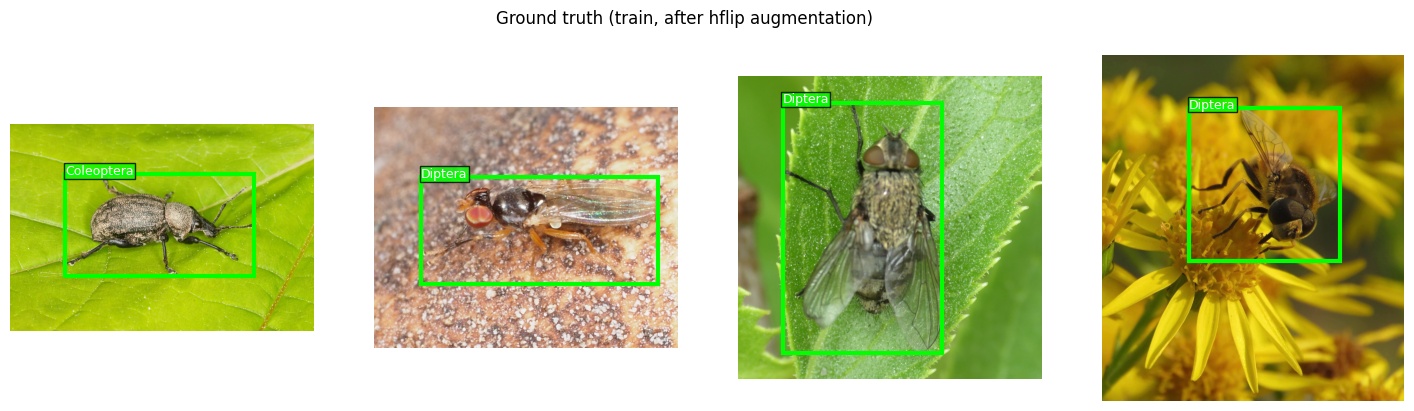

In [5]:
import matplotlib.patches as patches
def draw(ax, img, boxes, labels, color, scores=None):
    ax.imshow(img.permute(1, 2, 0).numpy())
    for i, (b, l) in enumerate(zip(boxes.tolist(), labels.tolist())):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec=color, lw=3))
        txt = dm.idx_to_class[int(l)] + (f" {scores[i]:.2f}" if scores is not None else "")
        ax.text(b[0], b[1], txt, color="white", fontsize=9, bbox=dict(fc=color, alpha=.8, pad=1))
    ax.axis("off")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, i in zip(axes, [0, 1, 2, 3]):
    img, t = dm.train_ds[i]
    draw(ax, img, t["boxes"], t["labels"], "lime")
fig.suptitle("Ground truth (train, after hflip augmentation)"); plt.show()

## 2. Training with per-epoch validation metrics
A callback records train loss and val mAP / mAP@50 after every epoch. `trainer.validate` before training gives the epoch-0 baseline (COCO backbone, untrained new classifier head).

In [6]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

class FasterRCNNLitFull(odp.FasterRCNNLit):
    # Same model/training as the pipeline; only keeps the FULL torchmetrics result (mAP@75, recall,
    # per-class AP) after every validation pass, so we can show more than mAP and mAP@50.
    def __init__(self, *a, **kw):
        super().__init__(*a, **kw)
        self.map_metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)
        self.full = []                       # one dict per validation pass (0 = baseline)
    def on_validation_epoch_end(self):
        self.full.append({k: v.detach().cpu() for k, v in self.map_metric.compute().items()})
        super().on_validation_epoch_end()    # logs val/map, val/map_50, resets the metric

class History(Callback):
    def __init__(self):
        self.rows, self.losses, self.loss_parts = [], [], []
    def on_train_epoch_end(self, trainer, pl_module):
        m = trainer.callback_metrics
        self.losses.append(m["train/loss_epoch"].item())
        self.loss_parts.append({k.split("/")[1]: v.item() for k, v in m.items()
                                if k.startswith("train/loss_") and not k.endswith(("_epoch", "_step"))})
    def on_validation_end(self, trainer, pl_module):
        if trainer.sanity_checking:
            return
        m = trainer.callback_metrics
        self.rows.append(dict(map=m["val/map"].item(), map50=m["val/map_50"].item()))

dm = odp.ArTaxOrDataModule(DATA_DIR, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED,
                           pin_memory=ACCELERATOR == "gpu")
dm.setup()
lit = FasterRCNNLitFull(num_classes=len(dm.class_to_idx) + 1, lr=LR)
hist = History()
lim = lambda x: int(x) if x > 1 else x
trainer = pl.Trainer(max_epochs=EPOCHS, accelerator=ACCELERATOR, devices=1 if ACCELERATOR != "cpu" else "auto",
                     callbacks=[hist, TQDMProgressBar(refresh_rate=20)], logger=False, enable_checkpointing=False,
                     num_sanity_val_steps=0, log_every_n_steps=20,
                     limit_train_batches=lim(TRAIN_BATCHES), limit_val_batches=lim(VAL_BATCHES))

trainer.validate(lit, datamodule=dm, verbose=False)      # epoch 0 = before any training
baseline = hist.rows[-1]
print("baseline:", baseline)

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 256MB/s]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Validation: |          | 0/? [00:00<?, ?it/s]

baseline: {'map': 0.0013534441823139787, 'map50': 0.006183250807225704}


In [7]:
t0 = time.time()
trainer.fit(lit, datamodule=dm)
print(f"trained {EPOCHS} epochs in {(time.time()-t0)/60:.1f} min")

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type                 ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model      │ FasterRCNN           │ 19.0 M │ train │     0 │
│ 1 │ map_metric │ MeanAveragePrecision │      0 │ train │     0 │
└───┴────────────┴──────────────────────┴────────┴───────┴───────┘

Trainable params: 18.9 M                                                                                           
Non-trainable params: 58.9 K                                                                                       
Total params: 19.0 M                                                                                               
Total estimated model params size (MB): 75.844                                                                     
Modules in train mode: 281                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=3` reached.


trained 3 epochs in 70.9 min


## 3.1 Proof: validation metrics vs. epoch

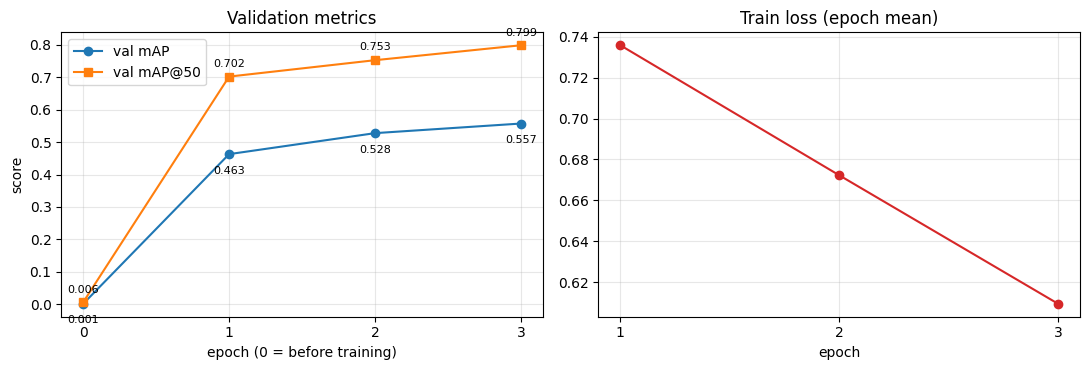

epoch 1: mAP 0.4629 (+0.4615)   mAP@50 0.7020 (+0.6958)
epoch 2: mAP 0.5276 (+0.0647)   mAP@50 0.7526 (+0.0506)
epoch 3: mAP 0.5572 (+0.0296)   mAP@50 0.7986 (+0.0460)

OK: val mAP and mAP@50 increase after every epoch -> the model is learning.


In [8]:
rows = hist.rows                               # [baseline, epoch1, ..., epochN]
epochs = list(range(len(rows)))
maps  = [r["map"] for r in rows]
map50 = [r["map50"] for r in rows]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(epochs, maps, "o-", label="val mAP")
ax[0].plot(epochs, map50, "s-", label="val mAP@50")
ax[0].set_xlabel("epoch (0 = before training)"); ax[0].set_xticks(epochs); ax[0].set_ylabel("score")
ax[0].set_title("Validation metrics"); ax[0].grid(alpha=.3); ax[0].legend()
for e, a, b in zip(epochs, maps, map50):
    ax[0].annotate(f"{a:.3f}", (e, a), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)
    ax[0].annotate(f"{b:.3f}", (e, b), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
loss = hist.losses
ax[1].plot(range(1, len(loss) + 1), loss, "o-", color="tab:red")
ax[1].set_xlabel("epoch"); ax[1].set_xticks(range(1, len(loss) + 1)); ax[1].set_title("Train loss (epoch mean)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("val_metrics.png", dpi=120); plt.show()

for i in range(1, len(rows)):
    print(f"epoch {i}: mAP {maps[i]:.4f} ({maps[i]-maps[i-1]:+.4f})   mAP@50 {map50[i]:.4f} ({map50[i]-map50[i-1]:+.4f})")

assert all(maps[i] > maps[i-1] for i in range(1, len(maps))), "val mAP did not increase every epoch"
assert all(map50[i] > map50[i-1] for i in range(1, len(map50))), "val mAP@50 did not increase every epoch"
print("\nOK: val mAP and mAP@50 increase after every epoch -> the model is learning.")

torch.save(lit.model.state_dict(), "frcnn_artaxor.pt")
import json; json.dump(rows, open("metrics.json", "w"), indent=1)

## 3.2 More evidence: recall, mAP@75, loss components, per-class AP

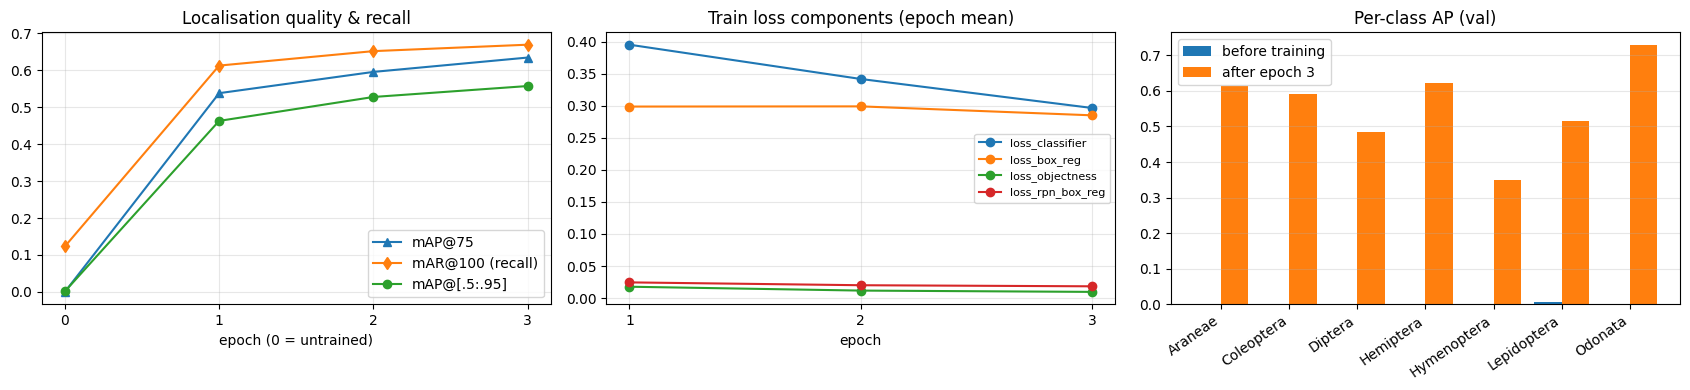

epoch     mAP  mAP@50  mAP@75  mAR@100
    0 0.0014 0.0062 0.0001 0.1232
    1 0.4629 0.7020 0.5379 0.6126
    2 0.5276 0.7526 0.5955 0.6517
    3 0.5572 0.7986 0.6343 0.6691

per-class AP (after training): {'Araneae': 0.612, 'Coleoptera': 0.59, 'Diptera': 0.485, 'Hemiptera': 0.621, 'Hymenoptera': 0.349, 'Lepidoptera': 0.515, 'Odonata': 0.728}
OK: recall, mAP@75 and every class improved vs. untrained baseline.


In [9]:
full = lit.full                                 # [baseline, epoch1, ..., epochN]
ep = list(range(len(full)))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

# (a) strict-IoU AP and recall
for key, label, mk in [("map_75", "mAP@75", "^-"), ("mar_100", "mAR@100 (recall)", "d-"), ("map", "mAP@[.5:.95]", "o-")]:
    ax[0].plot(ep, [f[key].item() for f in full], mk, label=label)
ax[0].set_title("Localisation quality & recall"); ax[0].set_xlabel("epoch (0 = untrained)"); ax[0].set_xticks(ep)
ax[0].grid(alpha=.3); ax[0].legend()

# (b) training loss components
for k in hist.loss_parts[0]:
    ax[1].plot(range(1, len(hist.loss_parts) + 1), [p[k] for p in hist.loss_parts], "o-", label=k)
ax[1].set_title("Train loss components (epoch mean)"); ax[1].set_xlabel("epoch")
ax[1].set_xticks(range(1, len(hist.loss_parts) + 1)); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)

# (c) per-class AP@[.5:.95]: before vs after training
names = [dm.idx_to_class[int(c)] for c in full[-1]["classes"]]
x = range(len(names)); w = 0.4
ax[2].bar([i - w/2 for i in x], full[0]["map_per_class"].clamp(min=0), w, label="before training")
ax[2].bar([i + w/2 for i in x], full[-1]["map_per_class"].clamp(min=0), w, label=f"after epoch {len(full)-1}")
ax[2].set_xticks(list(x)); ax[2].set_xticklabels(names, rotation=35, ha="right"); ax[2].set_title("Per-class AP (val)")
ax[2].grid(alpha=.3, axis="y"); ax[2].legend()
plt.tight_layout(); plt.savefig("extra_metrics.png", dpi=120); plt.show()

print(f"{'epoch':>5} {'mAP':>7} {'mAP@50':>7} {'mAP@75':>7} {'mAR@100':>8}")
for i, f in enumerate(full):
    print(f"{i:>5} {f['map']:.4f} {f['map_50']:.4f} {f['map_75']:.4f} {f['mar_100']:.4f}".replace("tensor(", "").replace(")", ""))
print("\nper-class AP (after training):", {n: round(v, 3) for n, v in zip(names, full[-1]["map_per_class"].tolist())})
assert full[-1]["mar_100"] > full[0]["mar_100"] and full[-1]["map_75"] > full[0]["map_75"]
assert all(v > 0 for v in full[-1]["map_per_class"].tolist()), "some class is not learned at all"
print("OK: recall, mAP@75 and every class improved vs. untrained baseline.")

## 4. Qualitative check: predictions vs. ground truth on validation images

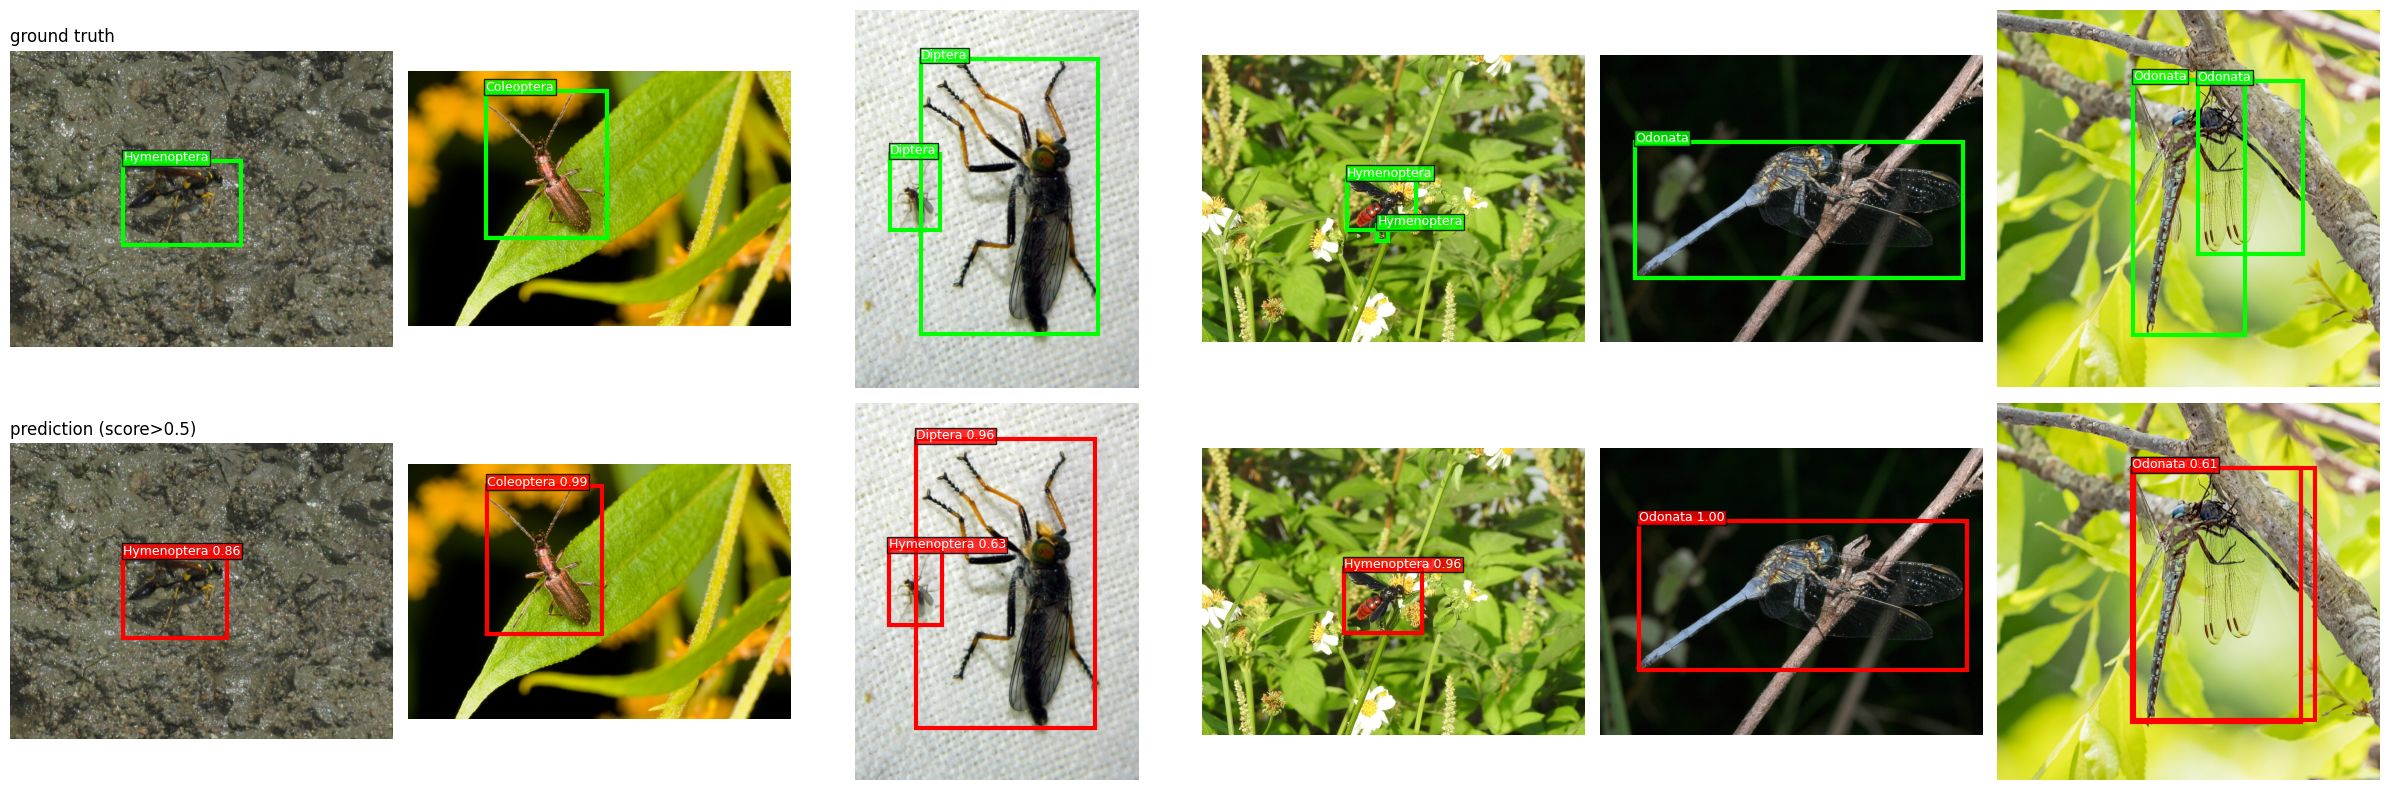

In [10]:
lit.eval(); dev = lit.device
imgs, gts = zip(*[dm.val_ds[i] for i in range(6)])
with torch.no_grad():
    preds = lit.model([im.to(dev) for im in imgs])
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for j in range(6):
    p = preds[j]; keep = p["scores"] > 0.5
    draw(axes[0, j], imgs[j], gts[j]["boxes"], gts[j]["labels"], "lime")
    draw(axes[1, j], imgs[j], p["boxes"][keep].cpu(), p["labels"][keep].cpu(), "red", p["scores"][keep].cpu())
axes[0, 0].set_title("ground truth", loc="left"); axes[1, 0].set_title("prediction (score>0.5)", loc="left")
plt.tight_layout(); plt.show()